# How wide is the range of outcomes? A Monte Carlo look at two stock-picking rules

A back-test gives you **one** history: one sequence of good and bad years. If the 2010s had gone differently, would the answer change? This notebook asks that question by **resampling**: it cuts the 1990-2022 market history into 12-month blocks and shuffles them into 1,000 alternative 20-year "futures" that look statistically like the past. Every portfolio, and the S&P 500 index, is then run through **exactly the same 1,000 futures**, so the comparison is fair: when a portfolio trails the index, it trails it in the same market.

What you will see, in order:

1. the data and its warnings (read these first);
2. a table of typical and extreme outcomes;
3. a fan chart of how wealth could grow;
4. how 10-year growth rates are spread out, portfolio against index;
5. the same, but as the difference on each individual path;
6. how deep the worst fall is, portfolio against index.

The two rules are **momentum** (each month hold the 5 stocks that rose most over the past year, skipping the latest month) and **low volatility** (hold the 5 calmest). Each is run twice: plain, and with a **trend exit** that moves to cash when the market index falls below a fixed trend threshold (fixed in advance in `research/CALIBRATION_SP500.md`, not tuned on these paths). Costs are included: 25 bps per trade, 5 bps to switch to or from cash.

Run all cells; about 20 seconds. Nothing is written to disk, nothing leaves your machine.

In [1]:
import sys, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import screenlab
except ImportError:                       # running from a git checkout without installing the package
    sys.path.insert(0, str(Path.cwd().parent.parent))
    import screenlab
from screenlab.realdata.bundled import sp500_lab
from screenlab.research.montecarlo_sp500 import policy, chart_fan, INDEX
from screenlab.research import montecarlo_histograms as H

N_PATHS = 1000                            # fewer (e.g. 300) is faster and a bit noisier
HORIZONS = [5, 10, 20]                    # years
%matplotlib inline
plt.rcParams["figure.dpi"] = 80

## 1. Run the simulation

`lab.montecarlo(...)` draws the paths once and runs both rules (with and without the exit) and the index on them. `seed` fixes the draw, so you get the same numbers every time.

In [2]:
t0 = time.time()
lab = sp500_lab(benchmark="price", allow_price_benchmark=True)   # the raw price index on purpose: the figures show it beside "index + ~2% div"
res = lab.montecarlo(["momentum_12_1", "low_vol"], n_paths=N_PATHS, horizon_years=HORIZONS,
                     start_wealth=100_000, exit=policy(), with_and_without=True, seed=20240,
                     rebalance_months=1, cost_bps=25.0)
per_path = H.prepare(res.per_path)        # one row per portfolio, horizon and path (adds a ~2%/yr dividend index)
print(f"{N_PATHS:,} paths simulated in {time.time() - t0:.0f} s")

1,000 paths simulated in 6 s


## 2. The data card and its warnings

Read these before any number below. They are not boilerplate: the two big ones change what the results mean.

In [3]:
print(res.data_card.line())
print()
for w in res.warnings:
    print("-", w)

Data: sp500_bundled, 1990-01-02..2022-12-28, 20 names, benchmark SP500 (price), PIT n/a, delisted no, survivorship +10.1%/yr

- WARNING: benchmark SP500 is a price index (dividends left out) but the portfolios are total return, so excess return is overstated by about the index's dividend yield. Use a total-return benchmark, or IndexBenchmark('SP500', dividend_yield=0.02) for an approximation.
- WARNING: survivorship score +10.1%/yr: an equal-weight basket of this dataset's names beat its benchmark by that much, so it probably holds survivors chosen with hindsight and results are likely flattered.
- Monte Carlo note: resampling reproduces the data it is drawn from, so every bias of the base dataset (survivors, price-only index, ...) is inherited by every path.
- Steps are month-ends: daily-clock rules (weekly exit checks, 10-day holds) act at monthly granularity.


**In plain words.** The 20 stocks are large companies that were still around in 2022, so the sample leaves out the ones that failed (*survivorship*). The package measures this: those 20 stocks beat the index by about **10 percentage points a year** by themselves. And the index here is a *price* index that leaves out dividends, worth about 2 points a year. Both flatter the portfolios. The package normally refuses to compare against a price index (the code cell above opts in with `allow_price_benchmark=True`), and its default benchmark adds the 2 points back (`IndexBenchmark("SP500", dividend_yield=0.02)`); this notebook asks for the raw index so that it can show both lines side by side.

## 3. The table: typical and extreme outcomes

Columns: growth per year (CAGR) at the 5th, 50th (median) and 95th percentile; how often the portfolio ends behind the index; how often its worst fall exceeds 30% or 50%. A 5th percentile of x means 1 path in 20 did worse than x.

In [4]:
t = res.table.reset_index()
t = t[t.horizon_years == 10].set_index("portfolio")
show = pd.DataFrame({
    "Median CAGR": t["CAGR_p50"], "Bad case (5th pct)": t["CAGR_p5"], "Good case (95th pct)": t["CAGR_p95"],
    "Median end wealth (from 100k)": t["TermWealth_p50"],
    "Ends behind index": t["P(trail)"], "Fall worse than -30%": t["P(MaxDD<-30%)"],
    "Fall worse than -50%": t["P(MaxDD<-50%)"]})
fmt = {c: "{:.1%}" for c in show.columns}
fmt["Median end wealth (from 100k)"] = "{:,.0f}"
print("10-year horizon, all paths")
display(show.style.format(fmt, na_rep="-"))

10-year horizon, all paths


,Median CAGR,Bad case (5th pct),Good case (95th pct),Median end wealth (from 100k),Ends behind index,Fall worse than -30%,Fall worse than -50%
portfolio,,,,,,,
momentum_12_1,17.7%,4.8%,33.2%,"508,747",2.8%,58.5%,11.5%
momentum_12_1+exit,14.2%,4.7%,26.4%,"376,079",10.9%,31.0%,2.4%
low_vol,12.4%,4.3%,21.1%,"322,787",12.3%,21.7%,0.5%
low_vol+exit,9.9%,3.2%,16.7%,"257,059",32.4%,5.1%,0.0%
SP500,7.6%,-1.4%,16.1%,"208,924",-,48.5%,12.2%


## 4. The fan chart: how wealth could grow

Start with 100,000. The line is the median path; the dark band holds the middle half of the paths and the light band 90% of them. The grey band is the index on the same paths. The y-axis is logarithmic, so equal steps are equal percentage gains.

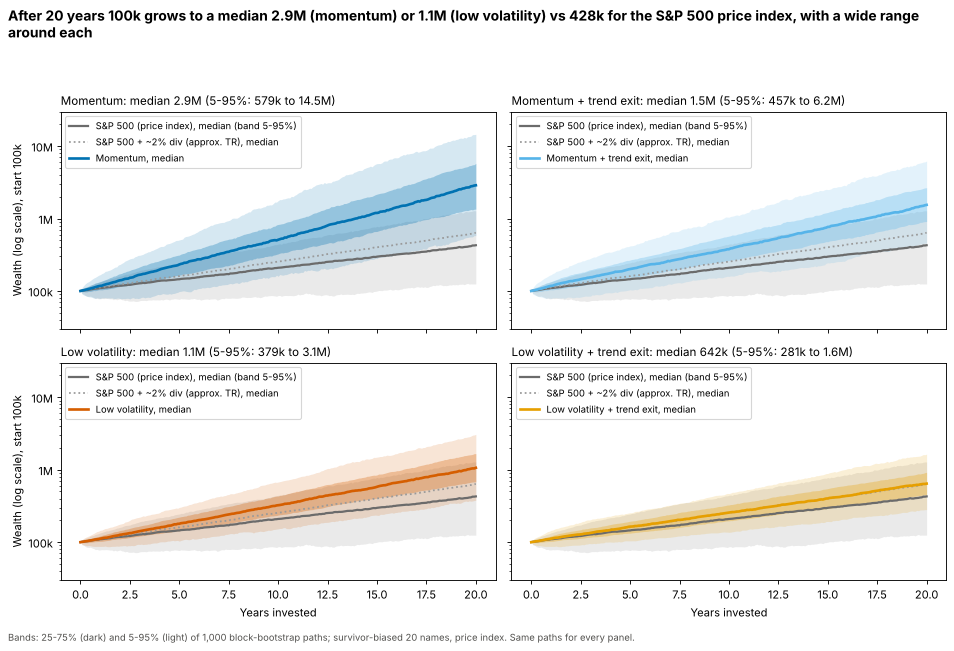

In [5]:
fig = chart_fan(res)
display(fig); plt.close(fig)

## 5. Growth rates, portfolio against index

Each panel overlays the distribution of 10-year growth per year: the portfolio in colour, the S&P 500 in grey, over the same paths. Vertical lines are medians. The more the colour sits to the right of the grey, the better; the width is the uncertainty.

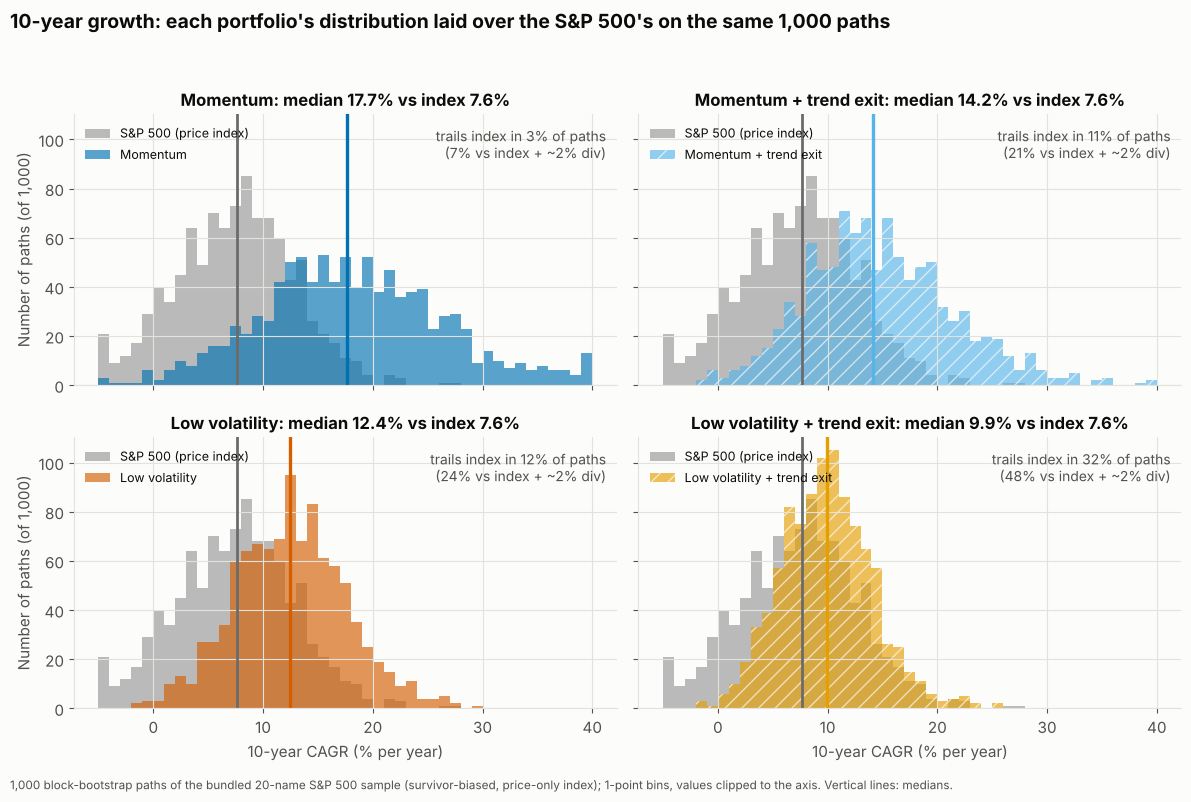

In [6]:
fig = H.fig5_cagr_vs_index(per_path)
display(fig); plt.close(fig)

## 6. The same comparison, path by path

Section 5 compares two piles of numbers. This one subtracts: for each path, portfolio growth minus index growth in that very market. Colour bars are paths where the portfolio finished ahead; grey bars, behind. The dotted line at +2 points marks roughly where the portfolio would be behind an index that included dividends.

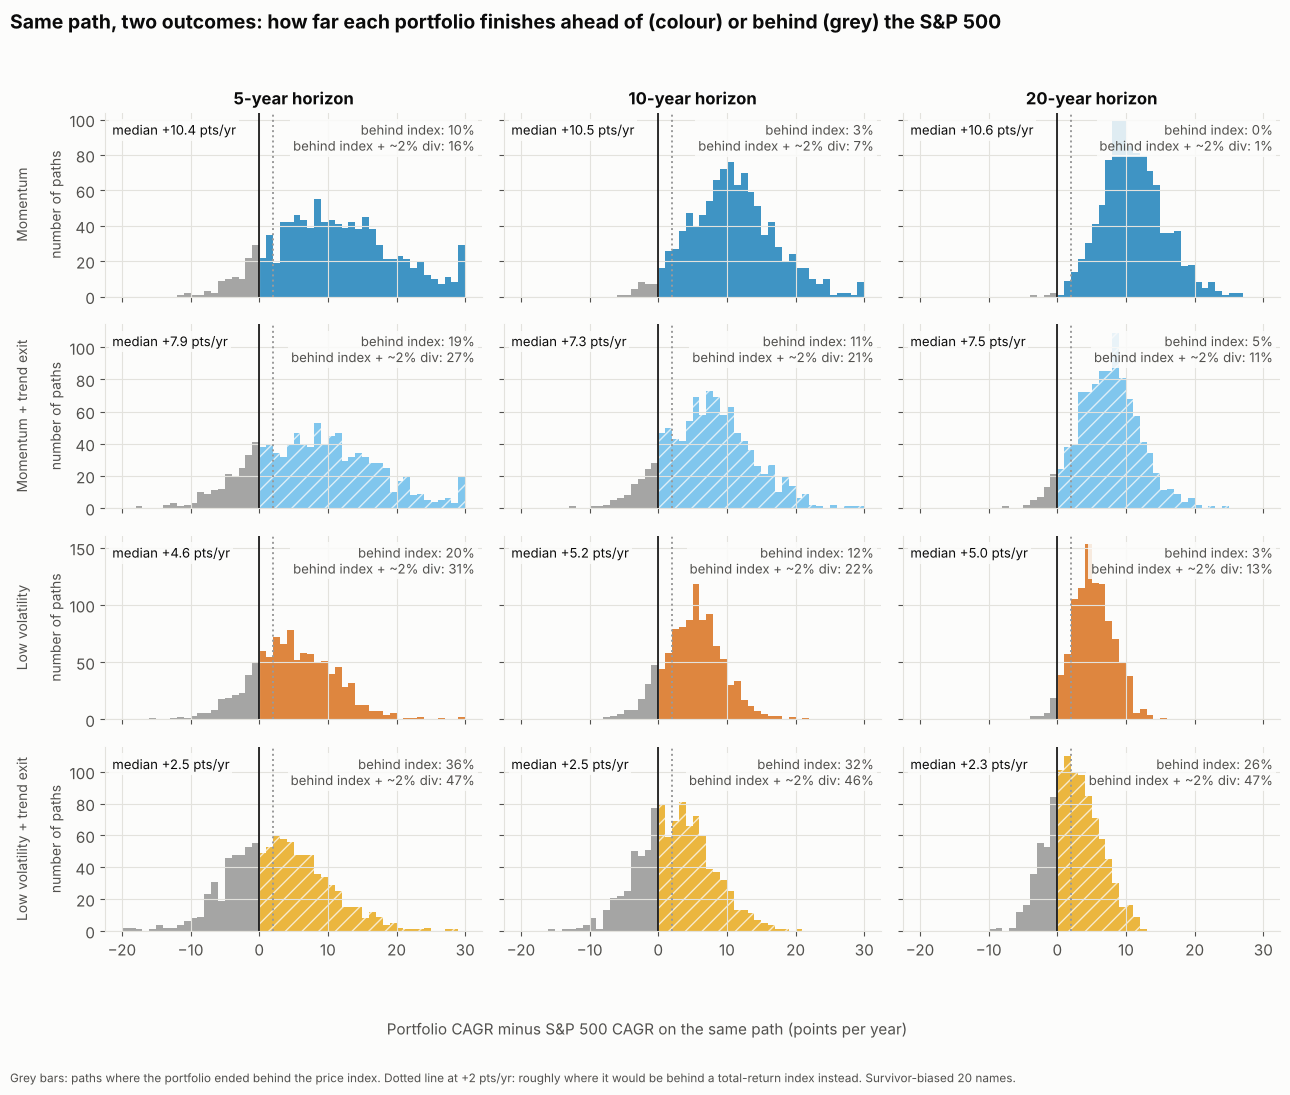

In [7]:
fig = H.fig6_paired_excess(per_path)
display(fig); plt.close(fig)

## 7. How deep is the worst fall?

Growth is half the story; the other half is what you must sit through. For every path this is the **worst peak-to-trough fall within 10 years** (measured at month-ends). Dotted lines mark -30% and -50%; the box counts how many paths fell that far.

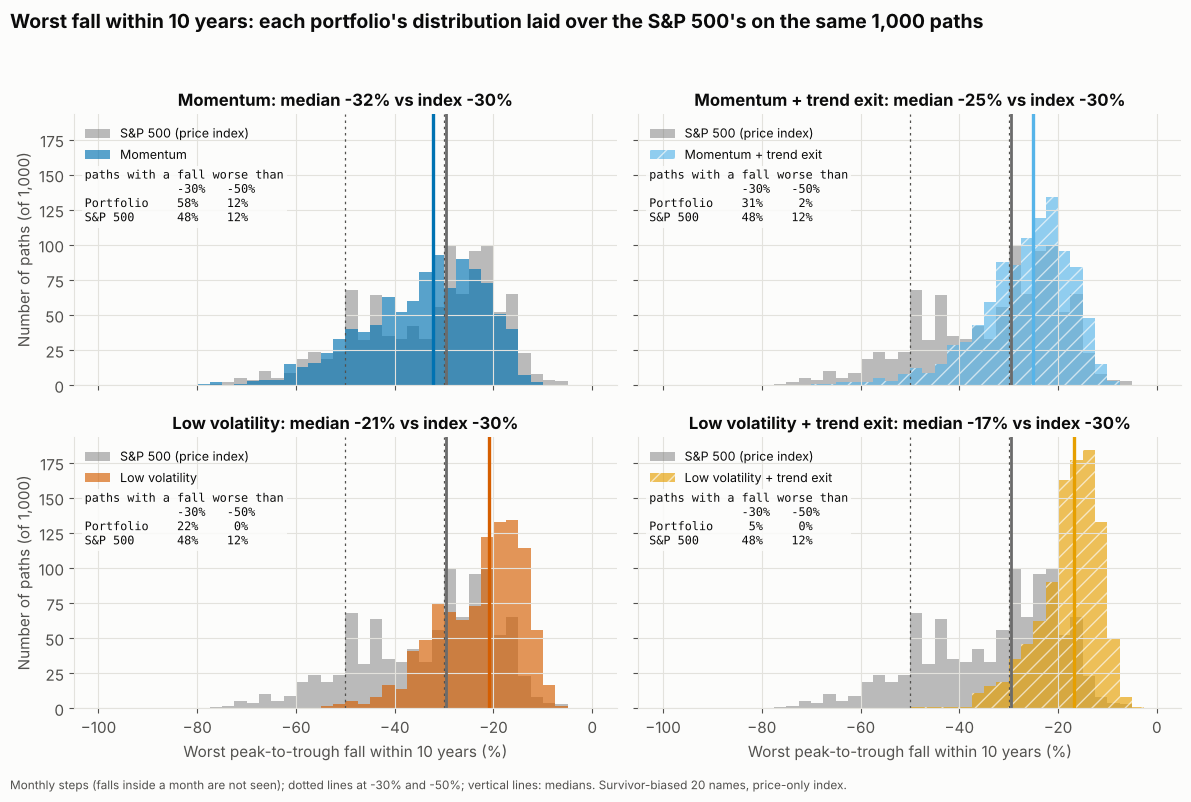

In [8]:
fig = H.fig7_drawdown_vs_index(per_path)
display(fig); plt.close(fig)

And path by path: right of zero, the portfolio's worst fall was milder than the index's in the same market. This shows something the previous chart cannot: whether a portfolio is hurt in the *same* markets as the index (a bunched histogram near zero) or in *different* ones.

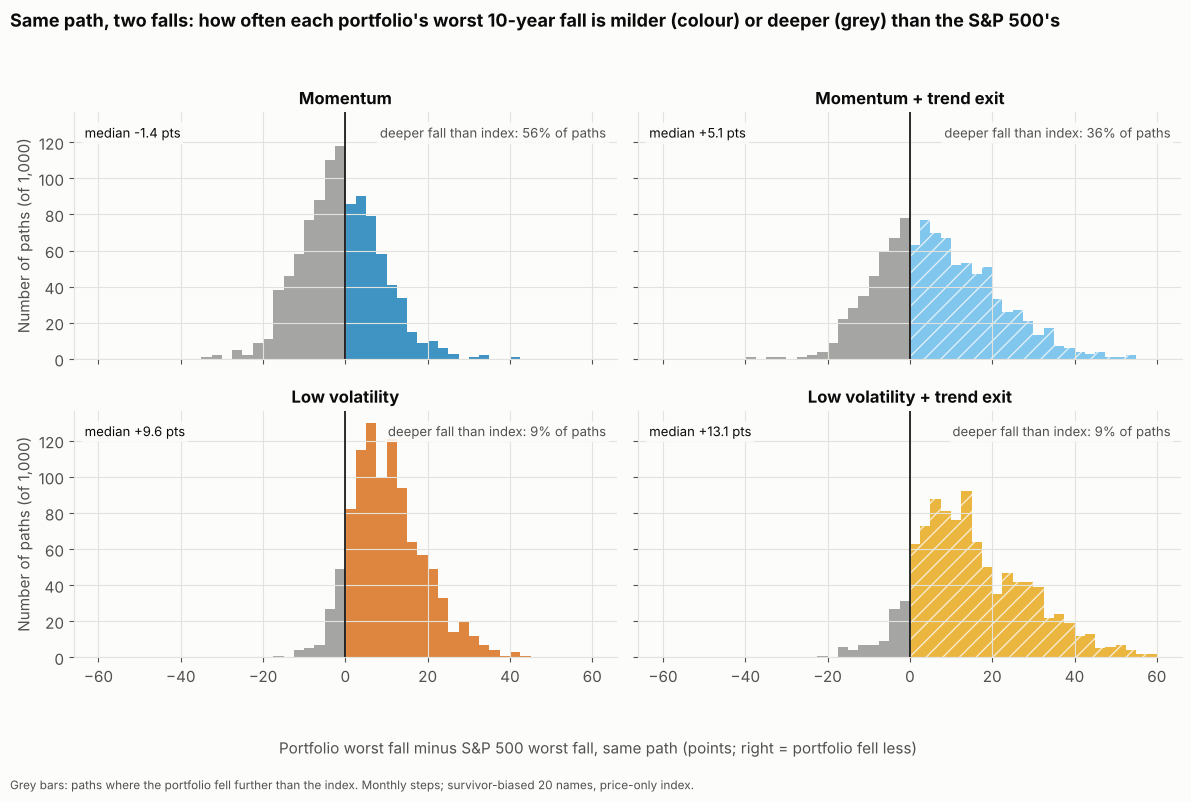

In [9]:
fig = H.fig7b_paired_drawdown(per_path)
display(fig); plt.close(fig)

## How to read this

* **Medians describe the typical future; the 5th and 95th percentiles describe the bad and good luck.** The range is wide: over 10 years the 5-to-95 spread of growth is many points per year, even for the calm portfolio.
* **"Ends behind index" is the question that matters to a saver**: not "what is the average" but "how often would I have regretted this choice". Compare it with the 2-point dividend line in section 6.
* **A trend exit trades growth for shallower falls.** Compare the plain and "+ trend exit" panels in section 7: the deep falls shrink. Whether the cost in growth is worth it is your call.
* **Same seed, same answer.** Change `N_PATHS` or `seed` to see how much the numbers move from sampling noise alone.

## What this cannot tell you

* **Survivorship, about +10 points a year.** The 20 stocks are winners selected with hindsight. Resampling cannot repair that: every simulated future inherits it. The portfolios' edge over the index here is about the size of the bias, so it is **not** evidence of skill and **not** a forecast.
* **A price-only index.** Dividends are left out of the S&P 500 line (about 2 points a year). Using the dotted +2 line in section 6 is a rough correction, not an exact one.
* **The future need not look like 1990-2022.** Blocks of past years can only recombine what already happened. A crash unlike any in the sample cannot appear, and the 12-month block length means long slumps are only as long as the sample's.
* **Month-end steps.** Falls inside a month and daily trend-exit rules are approximated.
* **Only 20 stocks and 5 holdings.** A portfolio of 5 of 20 is concentrated; results for a broad market would differ.

See `research/montecarlo/MONTECARLO_SP500.md` for the full study (other resampling methods, 1,000-path tables) and `CRITIQUE.md` for what the package can and cannot support.